# MIMIC-III phenotyping: how vendi-q2 (grad, rbf-median, L2) finds more positives

On `mimic3_pheno` at acq_size=250 (SAND, all cohort, 250 -> 2500 labels, 3 seeds), `vq2-grad-l2-med` ranks near the
top of 17 methods on AUPRC for conduction disorders (07), congestive heart failure (08), diabetes without complication
(11), upper respiratory disease (19) and septicemia (23). This notebook shows why: it labels many more positives of
those conditions. The full per-condition analysis is in `mimic3_pheno_250_vendi_per_condition.ipynb`.

**Why L2 changes what gets picked.** The gradient embedding of a stay is the outer product `e (x) h`:
`h` = penultimate features, and `e_k = sigmoid(z_k) - 1[sigmoid(z_k) > 0.5]` for each of the 25 conditions, so
`|e_k|` is largest when the model says ~0.5 for condition k. L2 normalization divides by `|e| |h|`, so the RBF
kernel between two stays depends only on `cos(e, e') * cos(h, h')`, i.e. on **which** conditions the model is unsure
about, not on **how much**.
- Without L2 (`none` / `minmax`), distances are dominated by the vector size, so vendi-q2 picks the stays with large
  features and uncertainty on many conditions: the acutely ill (shock, liver, respiratory failure).
- With L2, each stay counts equally. This `vendi-q2` scores each pool stay on its own by its squared kernel
  similarity to the labelled set, `sum_l K(x, l)^2`, and takes the 250 least similar (picks within a batch do not
  interact). So it picks stays whose uncertainty profile x feature direction is unlike every labelled stay's.
  Labelled stays are embedded with their true labels, so their profile is the model's remaining error on them.
  In practice the picks land on the chronic cardio-renal conditions (heart failure, conduction disorders, kidney
  disease, complicated hypertension), which the model finds hard to call from first-24h data.

**Methods compared.** Each one isolates part of the claim:
- `random`: the baseline; how many positives you get just by prevalence.
- `entropy`: **uncertainty without diversity**. It takes the stays with the highest summed per-condition uncertainty.
  If the L2 config's picks are driven by "which conditions is the model unsure about", entropy should over-sample the
  same conditions. If the diversity part matters, entropy should do worse with a similar number of positives.
- `vq2-grad-minmax-med`: **the same vendi-q2, gradient embedding and bandwidth, but magnitude kept** (min-max instead
  of L2). The only difference from the L2 config is the normalization, so it shows what L2 changes.

In [1]:
import ipynb_setup  # adds src/ to sys.path and loads .env
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wandb

from data.mimic_dataset import PHENO_CONDITION_NAMES

ROOT = Path("..")
L2, MINMAX = "vq2-grad-l2-med", "vq2-grad-minmax-med"
COMPARE = ["random", "entropy", MINMAX, L2]  # baseline, uncertainty only, same vendi-q2 with magnitude kept, L2
FOCUS = [7, 8, 11, 19, 23]

Y = np.load(Path(os.environ["DATA_ROOT"]) / "mimic3_sand/all/train/phenotype.npy")  # (n_pool, 25) multi-hot
NAMES = [n.split(";")[0].split("(")[0].strip() for n in PHENO_CONDITION_NAMES]

Loading .env from /home/jing/Desktop/realistic-al/.env


## Load runs

- **Runs:** from wandb. Methods are named `vq2-{grad|feat}-{normalization}-{gamma}` for vendi-q2.
- **Per-condition test AUPRC per round:** from `misc/phenotype_by_task_results/*__{wandb_id}.csv`.
- **Acquired stays:** `stored.npz["added_labels"]` in each run directory, shape (10 acquisitions, 250, 25). The
  first 9 acquisitions are the stays the final model trains on; the 10th is never trained on.

In [2]:
def method(q):
    if q["name"] != "vendi-q2":
        return q["name"]
    v = q["vendi"]
    return f"vq2-{'grad' if v['use_grad'] else 'feat'}-{v['normalization']}-{str(v['gamma'])[:3]}"


filters = {"config.data.name": "mimic3_pheno", "config.active.acq_size": 250, "state": "finished"}
runs = pd.DataFrame(
    dict(id=r.id, seed=r.config["trainer"]["seed"], method=method(r.config["query"]))
    for r in wandb.Api().runs("jingwusince01-national-taiwan-uni/realistic-al", filters=filters)
)
ids = lambda m: runs.id[runs.method == m]

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/jing/.netrc.


In [3]:
runs

,id,seed,method
0,svlbe3d4,12345,vq2-grad-none-med
1,bqr2z1ls,12345,vq2-grad-l2-med
2,uecset1s,12345,vq2-grad-minmax-med
3,pxqyt529,12345,vq2-grad-zscore-med
4,5ynsnnv2,12345,vq2-grad-zscore-dim
5,s4a54fi4,12345,vq2-grad-minmax-1
6,7jt39lmv,12346,vq2-grad-none-med
7,xx5zsc29,12345,random
8,qwa8iet6,12346,vq2-grad-minmax-1
9,irvv05na,12346,random


In [4]:
# per-condition test AUPRC for every round
csv = {f.stem.split("__")[-1]: f for f in (ROOT / "misc/phenotype_by_task_results").glob("*.csv")}
auprc = pd.concat(pd.read_csv(csv[r.id]).assign(method=r.method) for r in runs.itertuples()).query("metric == 'auprc'")
auprc["cond"] = auprc.condition.str[:2].astype(int)

# labels of the acquired stays: (9 acquisitions, 250 stays, 25 conditions)
run_dirs = ROOT / "experiments/activelearning/mimic3_pheno/active-mimic3_med"
wandb_id = lambda d: os.readlink(d / "wandb/latest-run").split("-")[-1]
run_dir = {wandb_id(d): d for d in run_dirs.glob("*/*start-250_step-250*/20*") if (d / "wandb/latest-run").exists()}
acq = {i: np.load(run_dir[i] / "stored.npz")["added_labels"][:9] for i in runs.id}

print(len(runs), "runs,", runs.method.nunique(), "methods")

51 runs, 17 methods


## Positives found vs AUPRC gain

- **gain:** AUBC of test AUPRC (mean over rounds 1-9) minus random's, paired by seed. All methods share the same
  initial labelled set within a seed.
- **t:** paired t-statistic over the 3 seeds.
- **pos_\*:** positives acquired among the 2250 acquired stays, mean over seeds.
- **atyp_l2:** comorbidity count of the positives L2 acquired, divided by that of a typical positive of the
  condition (> 1 means more multi-morbid than typical).

In [5]:
aubc = auprc[auprc.al_iter >= 1].groupby(["seed", "cond", "method"]).value.mean().unstack()
delta = aubc.sub(aubc["random"], axis=0)
gain = delta.groupby("cond").mean()

pos = pd.DataFrame({i: acq[i].sum((0, 1)) for i in runs.id}).T.join(runs.set_index("id").method).groupby("method").mean()

typical = np.array([Y[Y[:, c] == 1].sum(1).mean() for c in range(25)])
def atyp(a, c):
    a = a.reshape(-1, 25)
    return a[a[:, c] == 1].sum(1).mean() / typical[c]

story = pd.DataFrame({"name": NAMES, "prevalence": Y.mean(0)})
for m in COMPARE:
    story[f"pos_{m}"] = pos.loc[m]
story["atyp_l2"] = [np.mean([atyp(acq[i], c) for i in ids(L2)]) for c in range(25)]
story["gain_l2"] = gain[L2]
story["t_l2"] = delta[L2].groupby("cond").agg(lambda s: s.mean() / s.sem())
story["rank_l2_of_17"] = gain.rank(axis=1, ascending=False)[L2]
story.loc[FOCUS].round(3)

,name,prevalence,pos_random,pos_entropy,pos_vq2-grad-minmax-med,pos_vq2-grad-l2-med,atyp_l2,gain_l2,t_l2,rank_l2_of_17
7,Conduction disorders,0.075,181.667,270.333,190.333,322.000,1.103,0.010,1.919,1.0
8,Congestive heart failure,0.301,660.333,1085.333,858.667,1240.000,1.092,0.014,24.815,3.0
11,Diabetes mellitus without complication,0.196,452.000,578.667,502.333,626.667,1.180,0.007,3.636,1.0
19,Other upper respiratory disease,0.053,118.333,174.000,133.000,147.667,1.221,0.013,1.247,2.0
23,Septicemia,0.178,394.333,611.000,736.333,489.333,1.142,0.010,0.817,1.0


In [6]:
enrich = pos.loc[L2] / pos.loc["random"]
print(f"across all 25 conditions: Spearman(L2 over-sampling of a condition, its AUPRC gain) = "
      f"{enrich.corr(gain[L2], method='spearman'):+.2f}")

across all 25 conditions: Spearman(L2 over-sampling of a condition, its AUPRC gain) = +0.69


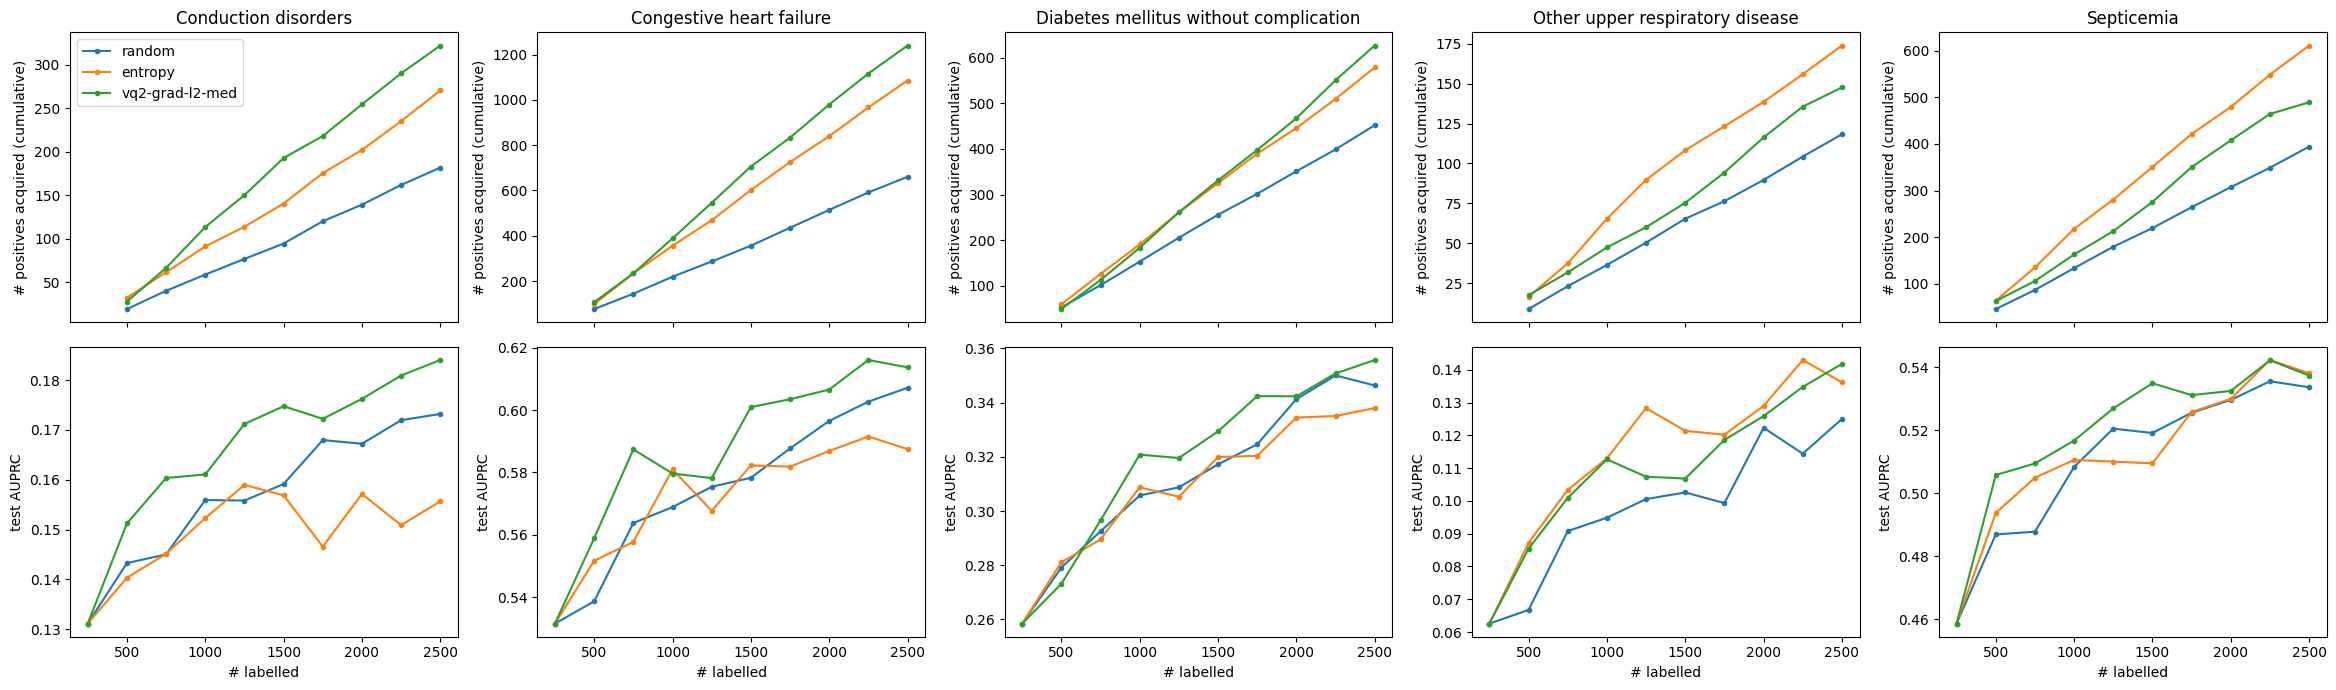

In [7]:
def plot_positives_and_auprc(conditions):
    fig, axes = plt.subplots(2, len(conditions), figsize=(4.7 * len(conditions), 7), sharex=True)
    n_labelled = 250 * np.arange(2, 11)  # labelled-set size after each of the 9 acquisitions
    for j, c in enumerate(conditions):
        for m in ["random", "entropy", L2]:
            found = np.mean([acq[i][:, :, c].sum(1).cumsum() for i in ids(m)], axis=0)
            axes[0, j].plot(n_labelled, found, marker=".", label=m)
            curve = auprc[(auprc.method == m) & (auprc.cond == c)].groupby("n_labelled").value.mean()
            axes[1, j].plot(curve.index, curve.values, marker=".", label=m)
        axes[0, j].set(title=NAMES[c], ylabel="# positives acquired (cumulative)")
        axes[1, j].set(xlabel="# labelled", ylabel="test AUPRC")
    axes[0, 0].legend()
    plt.tight_layout()


plot_positives_and_auprc(FOCUS)

**Reading the plots** (random, entropy, L2 config).
- **Positives found (top row):** on heart failure, conduction disorders and diabetes, the L2 config pulls away from
  random from the first acquisitions and ends with the most positives: heart failure ~1240 vs 660 for random,
  conduction ~320 vs 180, diabetes ~630 vs 450. Entropy also over-samples these conditions, but less. (Min-max
  vendi-q2 barely over-samples them, see the table: it goes after the acute cluster instead.)
- **AUPRC (bottom row):** on those three conditions the L2 config is above random for most of the curve. Diabetes
  converges back to random by the end.
- **More positives is not enough on its own.** Entropy labels the second-most positives on heart failure and
  conduction, yet ends *below* random on both. Both methods take a top-250 with no interaction between picks, so
  the difference is what they score. Entropy picks the stays with the most total uncertainty (ambiguous on many
  conditions at once). The L2 config picks stays whose uncertainty profile is unlike the labelled set's. Why the
  second set of positives is more useful is not tested here.
- **Upper respiratory (19) and septicemia (23)** are the weak cases. The L2 config finds more positives than random
  (~1.25x) and sits above random for much of the curve, but entropy finds even more positives and does about as well.
  So the gain here is not specific to L2, and it is within seed noise (t 1.2 and 0.8).
- **Across all 25 conditions the link holds:** the L2 config's over-sampling of a condition and its AUPRC gain
  correlate at rho +0.69 (printed above). Its positives are only mildly atypical (`atyp_l2` 1.09-1.18).

## The two robust cases: heart failure and diabetes

In [8]:
story["prev_rank"] = story.prevalence.rank(ascending=False).astype(int)  # 1 = most common of 25
print(f"median prevalence: {story.prevalence.median():.3f}")
story.loc[[8, 11], ["name", "prevalence", "prev_rank", "gain_l2", "t_l2"]].round(3)

median prevalence: 0.148


,name,prevalence,prev_rank,gain_l2,t_l2
8,Congestive heart failure,0.301,5,0.014,24.815
11,Diabetes mellitus without complication,0.196,10,0.007,3.636


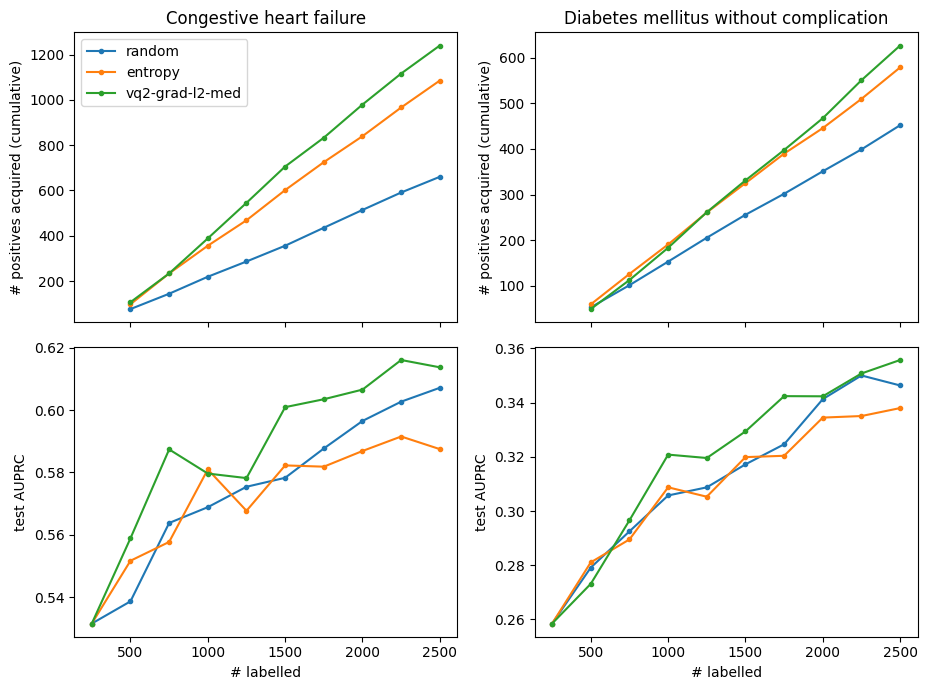

In [9]:
plot_positives_and_auprc([8, 11])  # heart failure, diabetes without complication

**Prevalence is not extreme.** Heart failure (30%) is the 5th most common of the 25 conditions and diabetes without
complication (20%) the 10th; the median is 15%. Both are common, not rare, so the gain is not a rare-label effect.
In both, the L2 config pulls ahead of random in positives found from the first acquisitions, and its AUPRC is above
random for most of the curve. Entropy finds almost as many positives and does not gain.

## More positives without a gain

Conditions where the L2 config acquires at least 1.2x random's positives but its AUPRC gain is at or below zero.
`headroom` = random's test AUPRC at 2500 labels minus at 250.

In [10]:
r = auprc[auprc.method == "random"].groupby(["cond", "n_labelled"]).value.mean().unstack()
story["headroom"] = r[2500] - r[250]
story["enrich_l2"] = enrich
no_gain = story[(story.enrich_l2 >= 1.2) & (story.gain_l2 <= 0)]
no_gain[["name", "prevalence", "enrich_l2", "gain_l2", "t_l2", "atyp_l2", "headroom"]].sort_values("enrich_l2", ascending=False).round(3)

,name,prevalence,enrich_l2,gain_l2,t_l2,atyp_l2,headroom
18,Other lower respiratory disease,0.064,1.557,-0.004,-6.939,1.195,0.028
0,Acute and unspecified renal failure,0.255,1.545,-0.005,-2.382,1.119,0.052
9,Coronary atherosclerosis and other heart disease,0.332,1.346,-0.030,-4.301,1.186,0.048
24,Shock,0.096,1.276,-0.004,-0.514,1.109,0.110
2,Acute myocardial infarction,0.115,1.275,-0.020,-4.636,1.151,0.171
20,Pleurisy,0.116,1.231,-0.005,-0.973,1.222,0.046
10,Diabetes mellitus with complications,0.099,1.209,-0.020,-1.892,1.222,0.132
12,Disorders of lipid metabolism,0.284,1.201,-0.017,-1.664,1.242,0.060


**Yes, several.** 19 conditions are over-sampled at least 1.2x, and 8 of them show no gain. The clearest cases:
- **Coronary atherosclerosis** (1.35x, about -0.030, t -4.3) and **acute myocardial infarction** (1.28x, -0.020,
  t -4.6) lose significantly despite more positives.
- **Other lower respiratory disease** (1.56x, -0.004, t -6.9) is a small but consistent loss.
- **Near misses not in the table:** COPD (1.86x) and chronic kidney disease (1.83x) are among the most over-sampled
  conditions yet gain only +0.001 and +0.006 (t < 0.4).

So over-sampling positives is associated with a gain (rho +0.69 across all 25) but is far from sufficient. Among the 19
over-sampled conditions, the gain tracks the amount of over-sampling (rho +0.44) and falls with how atypical the
positives are (rho -0.44); both p about 0.06, so weak. Six of the eight losers carry more multi-morbid positives
(`atyp_l2` 1.15-1.24) than heart failure (1.09), but renal failure and shock lose with fairly typical positives
(1.11-1.12) and diabetes gains at 1.18, so atypicality is only part of it. A plausible reading: coronary disease, AMI and lipid disorders co-occur with heart
failure, and the L2 config reaches their positives through heart-failure-like stays, so the extra positives do not
look like typical test positives. This is not tested here.


## Contrapositive: fewer positives, worse AUPRC

If finding positives is what drives the gains, the L2 config should lose where it finds *fewer* positives than
random. It under-samples 4 conditions, and it loses AUPRC on all 4.


In [11]:
fewer = story.assign(enrich_l2=enrich, gain_minmax=gain[MINMAX], gain_entropy=gain["entropy"])[enrich < 1]
fewer[["name", "prevalence", "pos_random", f"pos_{L2}", "enrich_l2", "gain_l2", "t_l2", "rank_l2_of_17",
       f"pos_{MINMAX}", "gain_minmax", "gain_entropy"]].sort_values("enrich_l2").round(3)

,name,prevalence,pos_random,pos_vq2-grad-l2-med,enrich_l2,gain_l2,t_l2,rank_l2_of_17,pos_vq2-grad-minmax-med,gain_minmax,gain_entropy
1,Acute cerebrovascular disease,0.080,174.333,98.000,0.562,-0.044,-4.655,5.0,201.667,-0.055,-0.066
17,Other liver diseases,0.112,252.000,182.667,0.725,-0.045,-3.108,17.0,516.000,0.029,-0.037
15,Gastrointestinal hemorrhage,0.082,185.667,158.333,0.853,-0.007,-1.021,4.0,291.333,-0.029,0.004
6,Complications of surgical procedures or medica...,0.267,614.667,555.667,0.904,-0.011,-3.815,16.0,742.667,0.009,-0.016


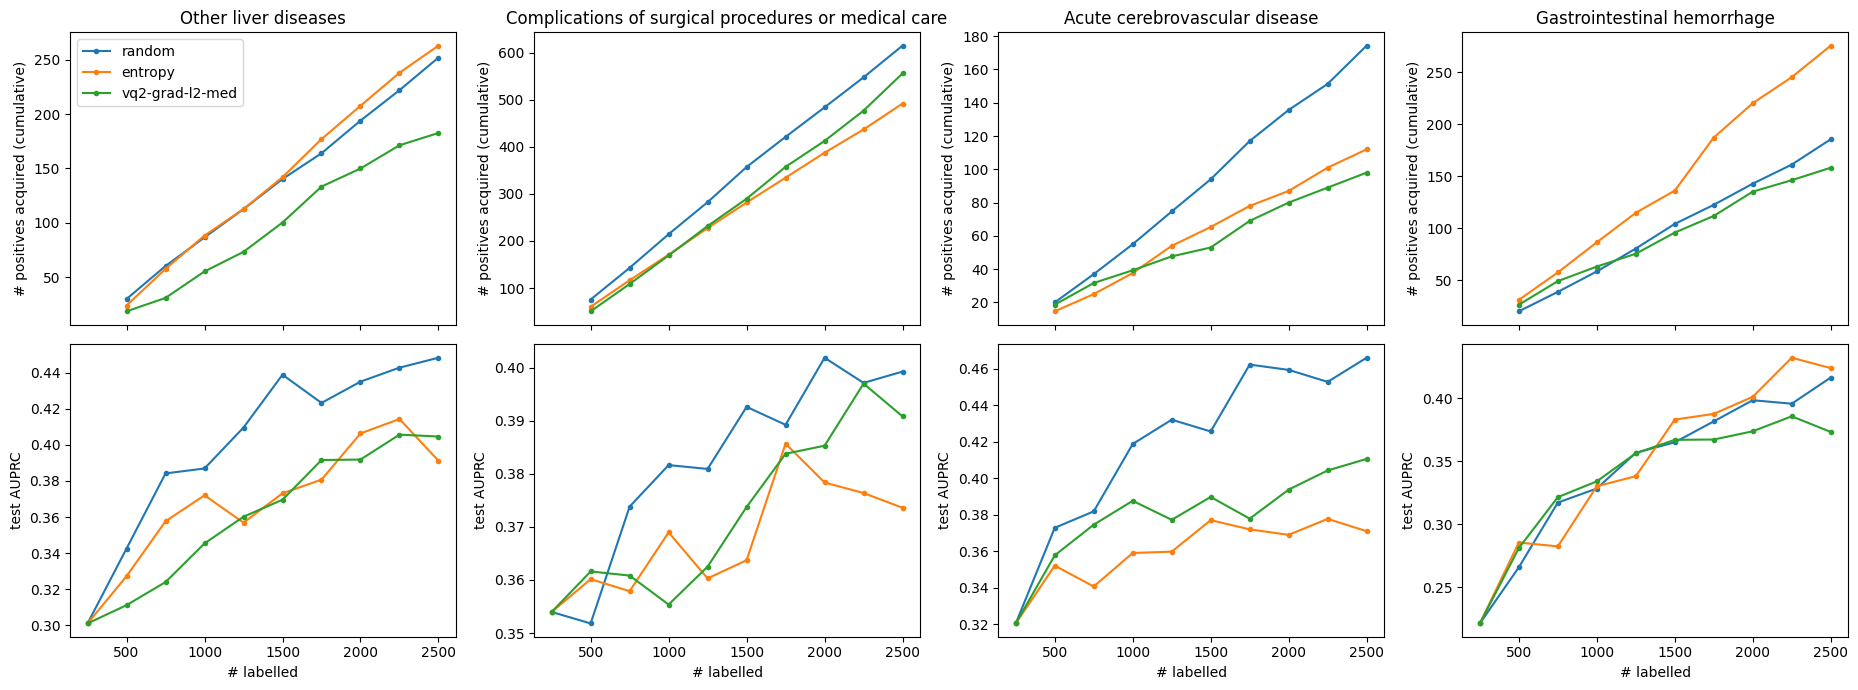

In [12]:
plot_positives_and_auprc([17, 6, 1, 15])  # liver, surgical complications, cerebrovascular, GI hemorrhage

**Reading the plots** (random, entropy, L2 config).
- **Liver disease is the clean case.** The L2 config finds the fewest positives from the first acquisition on
  (~0.73x random) and is below random throughout, ranking last of 17 (about -0.045, t about -3.1). From the table,
  min-max vendi-q2 (same method, magnitude kept) finds ~2x random's positives and gains about +0.03. So the
  normalization alone flips both the positives found and the result. Liver disease is an acute-cluster condition
  the model is fairly confident about, so it barely shows up in L2's "which conditions am I unsure about" direction.
- **Complications of surgical procedures** follow the same pattern on a smaller scale: 0.90x the positives, below
  random for most of the curve, 16th of 17 (t about -3.8).
- **Cerebrovascular disease is not clean.** L2 finds the fewest positives (0.56x) and loses, but every method loses
  here, including min-max with 1.16x the positives. That is the atypical-positive problem from the main notebook (the
  stroke patients the methods pick are more multi-morbid than typical ones), not just a count effect.
- **Gastrointestinal hemorrhage** (0.86x, about -0.007) is within seed noise.

**How far this goes.** Only heart failure (t ~ 25) and diabetes (t ~ 3.6) are robust with 3 seeds; conduction
disorders is borderline (t ~ 1.9). Upper respiratory (19) and septicemia (23) don't fit the story: on septicemia the
L2 config acquires *fewer* positives than entropy, min-max vendi-q2 or kcentergreedy yet comes out ahead, which
points to noise. Because the L2 config trades the acute conditions for the chronic ones, its average over all 25 conditions
is still below random.